In [2]:
import numpy as np
import pandas as pd
from func import*

In [3]:
#Find Current Working Directory
import os
os.getcwd()

'C:\\Users\\Elniajo\\Documents\\Cluster Analysis'

In [4]:
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X.head()

,mainspanmaterial_re,mainspandesign_re,lanes_re,Bridge_Age,Deck_Area,ADT,structure_length,type_of_work,ADTT_Percent,avg_relative_humidity,total_precipitation
Bridge_condition,,,,,,,,,,,
1,2,6,2,3,1,1,1,1,1,3,3
1,10,18,2,3,1,1,1,1,1,3,3
1,10,18,2,3,2,1,1,1,1,3,3
1,10,18,2,3,4,1,1,1,1,3,3
1,2,6,4,2,3,1,1,1,4,3,3


In [5]:
len(X)

30038

In [6]:
X = X.drop (["mainspandesign_re"],axis=1)
#X = X.drop (["type_of_work","mainspanmaterial_re","mainspandesign_re","lanes_re","Bridge_Age","structure_length","ADTT_Percent","avg_relative_humidity","total_precipitation"],axis=1)

In [7]:
X.head()

,mainspanmaterial_re,lanes_re,Bridge_Age,Deck_Area,ADT,structure_length,type_of_work,ADTT_Percent,avg_relative_humidity,total_precipitation
Bridge_condition,,,,,,,,,,
1,2,2,3,1,1,1,1,1,3,3
1,10,2,3,1,1,1,1,1,3,3
1,10,2,3,2,1,1,1,1,3,3
1,10,2,3,4,1,1,1,1,3,3
1,2,4,2,3,1,1,1,4,3,3


In [8]:
#df['Weather Condition Description'].value_counts()

#display(df.isnull().sum())



In [9]:
#X = original_data[['vol_lane','speed_bt','densit_lane']]
#X.head()

In [10]:
# Import the sklearn function
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-1.58470826,  0.1393929 ,  0.4374651 , ..., -1.27819099,
         0.97297217,  0.55975848],
       [ 1.30025097,  0.1393929 ,  0.4374651 , ..., -1.27819099,
         0.97297217,  0.55975848],
       [ 1.30025097,  0.1393929 ,  0.4374651 , ..., -1.27819099,
         0.97297217,  0.55975848],
       ...,
       [-1.58470826,  0.1393929 ,  0.4374651 , ...,  0.23027776,
        -0.85434671, -1.30556492],
       [-1.58470826,  0.1393929 ,  0.4374651 , ...,  0.23027776,
        -0.85434671, -1.30556492],
       [-1.58470826,  0.1393929 ,  0.4374651 , ...,  0.23027776,
        -0.85434671, -1.30556492]])

In [11]:
from sklearn.cluster import KMeans

In [12]:
# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to:
clusters =  kmeans.predict(X_scaled)


In [13]:
# Add cluster number to the original data
X_scaled_clustered = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
X_scaled_clustered['cluster'] = clusters

X_scaled_clustered.head()

,mainspanmaterial_re,lanes_re,Bridge_Age,Deck_Area,ADT,structure_length,type_of_work,ADTT_Percent,avg_relative_humidity,total_precipitation,cluster
Bridge_condition,,,,,,,,,,,
1,-1.584708,0.139393,0.437465,-0.858670,-0.102209,-0.324596,-0.676733,-1.278191,0.972972,0.559758,2
1,1.300251,0.139393,0.437465,-0.858670,-0.102209,-0.324596,-0.676733,-1.278191,0.972972,0.559758,2
1,1.300251,0.139393,0.437465,-0.319028,-0.102209,-0.324596,-0.676733,-1.278191,0.972972,0.559758,2
1,1.300251,0.139393,0.437465,0.760256,-0.102209,-0.324596,-0.676733,-1.278191,0.972972,0.559758,2
1,-1.584708,3.351579,-1.673471,0.220614,-0.102209,-0.324596,-0.676733,0.984512,0.972972,0.559758,4


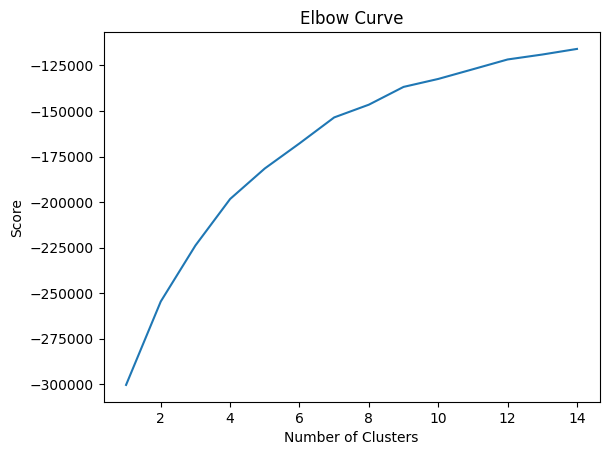

In [14]:
# Run a number of tests, for 1, 2, ... num_clusters
num_clusters = 15
kmeans_tests = [KMeans(n_clusters=i, init='random', n_init=10) for i in range(1, num_clusters)]
score = [kmeans_tests[i].fit(X_scaled).score(X_scaled) for i in range(len(kmeans_tests))]

# Plot the curve
plt.plot(range(1, num_clusters),score)
plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.title('Elbow Curve')
plt.show()

In [15]:
from sklearn.decomposition import PCA

# Create a PCA model to reduce our data to 2 dimensions for visualisation
pca = PCA(n_components=2)
pca.fit(X_scaled)

# Transfor the scaled data to the new PCA space
X_reduced = pca.transform(X_scaled)

In [16]:
# Convert to a data frame
X_reduceddf = pd.DataFrame(X_reduced, index=X.index, columns=['PC1','PC2'])
X_reduceddf['cluster'] = clusters
X_reduceddf.head()

,PC1,PC2,cluster
Bridge_condition,,,
1,-0.757233,1.046659,2
1,-0.907771,0.759810,2
1,-0.613132,0.670459,2
1,-0.023854,0.491755,2
1,1.874956,0.651584,4


In [17]:
centres_reduced = pca.transform(kmeans.cluster_centers_)

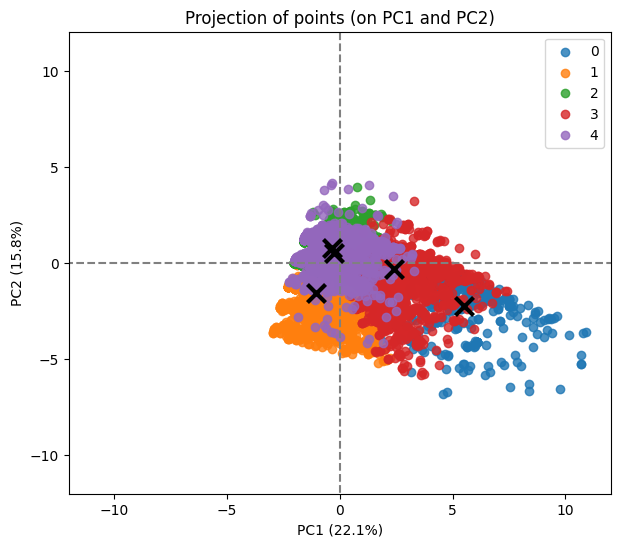

In [18]:
display_factorial_planes(X_reduced, 2, pca, [(0,1)], illustrative_var = clusters, alpha = 0.8)
plt.scatter(centres_reduced[:, 0], centres_reduced[:, 1],
            marker='x', s=169, linewidths=3,
            color='k', zorder=10)

In [19]:
# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

X_clustered.head()

category = pd.cut(X_clustered.mainspanmaterial_re,bins = [0,1,2,3,4,5,6,7,8,9,10],
                  labels=['Aluminium','Concrete','Concrete Continuous','Masonry','Other',"Prestressed concrete",
                          "Prestressed continuous","steel","steelcontinuous","timber"])


category1 = pd.cut(X_clustered.lanes_re,bins = [0,1,2,3,4],
                   labels=['One Lane','Two Lanes','Three Lanes','More than Three'])

category2 = pd.cut(X_clustered.Bridge_Age,bins = [0,1,2,3],
                   labels=['0 to 25','26 to 50','more than 50'])

category3 = pd.cut(X_clustered.Deck_Area,bins = [0,1,2,3,4,5,6],
                   labels=['0 to 1000', '1000 to 2000','2000 to 3000','4000 to 5000','5000 to 6000','more than 6000'])

category4 = pd.cut(X_clustered.ADT,bins = [0,1,2,3,4],
                   labels=['0 to 50k','50k to 100k','100k-200k','more than 200k'])

category5 = pd.cut(X_clustered.structure_length,bins = [0,1,2,3,4,5,6],
                   labels=['0 to 200','200 to 500','500 to 1000','1000 to 3000','3000 to 5000','more than 5000'])

category6 = pd.cut(X_clustered.type_of_work,bins = [0,1,2,3,4,5,6,7,8],
                   labels=['replace-load carrying capacity','replace-relocation','widen','widen-deck replace',
                           'rehab-deterioration','rehad-widen','deck replace','structural work'])

category7 = pd.cut(X_clustered.ADTT_Percent,bins = [0,1,2,3,4],
                   labels=['1%-2%','2%-3%','3%-5%','greater than 5%'])

category8 = pd.cut(X_clustered.avg_relative_humidity,bins = [0,1,2,3],
                   labels=['0-50%','50%-75%','more than 75%'])

category9 = pd.cut(X_clustered.total_precipitation,bins = [0,1,2,3,4,5],
                   labels=['0-500','500-1000','1000-2000','2000-3000','more than 3000'])

X_clustered.insert(1,'Construction_Material',category)
X_clustered.insert(2,'Number of Lanes',category1)
X_clustered.insert(3,'Bridge Age',category2)
X_clustered.insert(4,'Deck Area',category3)
X_clustered.insert(5,'Average_Daily_Traffic',category4)
X_clustered.insert(6,'Structure_Length',category5)
X_clustered.insert(7,'Work_Done',category6)
X_clustered.insert(8,'Truck_Percent',category7)
X_clustered.insert(9,'Avg_Relative_Humidity',category8)
X_clustered.insert(10,'Total_Precipitation',category9)

In [20]:
X_clustered.sample(10)

,mainspanmaterial_re,Construction_Material,Number of Lanes,Bridge Age,Deck Area,Average_Daily_Traffic,Structure_Length,Work_Done,Truck_Percent,Avg_Relative_Humidity,...,lanes_re,Bridge_Age,Deck_Area,ADT,structure_length,type_of_work,ADTT_Percent,avg_relative_humidity,total_precipitation,cluster
Bridge_condition,,,,,,,,,,,,,,,,,,,,,
1,10,timber,Two Lanes,0 to 25,0 to 1000,0 to 50k,0 to 200,replace-load carrying capacity,1%-2%,50%-75%,...,2,1,1,1,1,1,1,2,3,4
1,8,steel,Two Lanes,more than 50,1000 to 2000,0 to 50k,0 to 200,rehab-deterioration,1%-2%,50%-75%,...,2,3,2,1,1,5,1,2,3,2
1,2,Concrete,One Lane,more than 50,1000 to 2000,0 to 50k,0 to 200,replace-load carrying capacity,greater than 5%,50%-75%,...,1,3,2,1,1,1,4,2,3,2
1,2,Concrete,Two Lanes,more than 50,5000 to 6000,0 to 50k,0 to 200,replace-load carrying capacity,greater than 5%,more than 75%,...,2,3,5,1,1,1,4,3,3,2
1,6,Prestressed concrete,Two Lanes,more than 50,1000 to 2000,0 to 50k,0 to 200,replace-load carrying capacity,3%-5%,more than 75%,...,2,3,2,1,1,1,3,3,3,2
1,8,steel,Two Lanes,0 to 25,2000 to 3000,0 to 50k,0 to 200,rehab-deterioration,3%-5%,more than 75%,...,2,1,3,1,1,5,3,3,3,4
1,8,steel,Two Lanes,more than 50,1000 to 2000,0 to 50k,0 to 200,rehab-deterioration,greater than 5%,50%-75%,...,2,3,2,1,1,5,4,2,3,2
1,8,steel,One Lane,more than 50,0 to 1000,0 to 50k,0 to 200,replace-load carrying capacity,greater than 5%,50%-75%,...,1,3,1,1,1,1,4,2,3,2
1,2,Concrete,Two Lanes,more than 50,1000 to 2000,0 to 50k,0 to 200,replace-load carrying capacity,greater than 5%,more than 75%,...,2,3,2,1,1,1,4,3,3,2


In [21]:
X_clustered.to_csv('C:/Users/Elniajo/Documents/Cluster Analysis/NBI_Results.csv')

In [22]:
pip install networkx

Note: you may need to restart the kernel to use updated packages.


In [23]:
import numpy as np
import pandas as pd
import networkx as nx
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import scipy

# Load the dataset
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

# Convert categorical data to numerical using Label Encoding
X_encoded = X.copy()

categorical_columns = ['mainspanmaterial_re', 'lanes_re', 'Bridge_Age', 'Deck_Area', 'ADT', 'structure_length',
                       'type_of_work', 'ADTT_Percent', 'avg_relative_humidity', 'total_precipitation']
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    label_encoders[col] = le

# Scale the numerical features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Construct the graph adjacency matrix (use a similarity-based approach)
# Here, we define a simple similarity graph based on distance in the feature space
def build_adjacency_matrix(X, threshold=0.5):
    n = len(X)
    adj = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            similarity = np.linalg.norm(X[i] - X[j])
            if similarity < threshold:
                adj[i, j] = adj[j, i] = 1
    return adj

# Create the adjacency matrix
A = build_adjacency_matrix(X_scaled)

# Add self-loops (GCN standard)
I = np.eye(A.shape[0])
A_hat = A + I

# Degree matrix
D_hat = np.array(np.sum(A_hat, axis=0))
D_hat = np.diag(D_hat)

# GCN layers
def relu(x):
    return np.maximum(0, x)

def gcn_layer(A_hat, D_hat, X, W):
    D_inv_sqrt = np.linalg.inv(np.sqrt(D_hat))
    return relu(D_inv_sqrt @ A_hat @ D_inv_sqrt @ X @ W)

# Initialize weights for GCN layers
W_1 = np.random.normal(size=(X_scaled.shape[1], 16))  # Input to hidden layer
W_2 = np.random.normal(size=(16, 2))  # Hidden to output layer

# First GCN layer
H_1 = gcn_layer(A_hat, D_hat, X_scaled, W_1)

# Second GCN layer
H_2 = gcn_layer(A_hat, D_hat, H_1, W_2)

# Resulting node embeddings (bridge embeddings)
embeddings = H_2

# Clustering on GCN embeddings using K-Means
kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(embeddings)

# Add cluster labels to the original data
X_encoded['cluster'] = clusters

# Visualizing the results with PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(embeddings)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', alpha=0.7)
plt.colorbar(label='Cluster')
plt.title('GCN-based Clustering of Bridges')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

# Calculate risk based on key features
# We'll take an average of important features for each cluster to determine risk
climate_features = ['Bridge_Age', 'Deck_Area', 'avg_relative_humidity', 'total_precipitation']
X_encoded['risk_score'] = X_encoded[climate_features].mean(axis=1)

# Calculate average risk for each cluster
cluster_risks = X_encoded.groupby('cluster')['risk_score'].mean()

# Plotting the cluster risks
plt.figure(figsize=(8, 6))
plt.bar(range(len(cluster_risks)), cluster_risks, color='orange')
plt.title('Average Risk per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Risk Score')
plt.show()

# Saving the risk scores and clusters
X_encoded.to_csv('bridge_risk_scores_clusters.csv')


MemoryError: Unable to allocate 6.72 GiB for an array with shape (30038, 30038) and data type float64

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import scipy.sparse as sp

# Load the dataset
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

# Convert categorical data to numerical using Label Encoding
X_encoded = X.copy()

categorical_columns = ['mainspanmaterial_re', 'lanes_re', 'Bridge_Age', 'Deck_Area', 'ADT', 'structure_length',
                       'type_of_work', 'ADTT_Percent', 'avg_relative_humidity', 'total_precipitation']
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    label_encoders[col] = le

# Scale the numerical features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Construct the graph adjacency matrix (use sparse matrix to save memory)
# Here, we define a simple similarity graph based on distance in the feature space
def build_sparse_adjacency_matrix(X, threshold=0.5):
    n = len(X)
    adj = sp.lil_matrix((n, n))  # Use sparse matrix (LIL format allows efficient row operations)
    for i in range(n):
        for j in range(i + 1, n):
            similarity = np.linalg.norm(X[i] - X[j])
            if similarity < threshold:
                adj[i, j] = adj[j, i] = 1
    return adj

# Create the sparse adjacency matrix
A_sparse = build_sparse_adjacency_matrix(X_scaled)

# Add self-loops (GCN standard)
I_sparse = sp.eye(A_sparse.shape[0])
A_hat_sparse = A_sparse + I_sparse

# Degree matrix (sparse)
D_hat_sparse = np.array(A_hat_sparse.sum(axis=0)).flatten()
D_hat_sparse_inv_sqrt = sp.diags(np.power(D_hat_sparse, -0.5))

# GCN layers using sparse matrices
def gcn_layer_sparse(A_hat, D_hat_inv_sqrt, X, W):
    return np.maximum(0, D_hat_inv_sqrt @ A_hat @ D_hat_inv_sqrt @ X @ W)

# Initialize weights for GCN layers
W_1 = np.random.normal(size=(X_scaled.shape[1], 16))  # Input to hidden layer
W_2 = np.random.normal(size=(16, 2))  # Hidden to output layer

# First GCN layer
H_1_sparse = gcn_layer_sparse(A_hat_sparse, D_hat_sparse_inv_sqrt, X_scaled, W_1)

# Second GCN layer
H_2_sparse = gcn_layer_sparse(A_hat_sparse, D_hat_sparse_inv_sqrt, H_1_sparse, W_2)

# Resulting node embeddings (bridge embeddings)
embeddings_sparse = H_2_sparse

# Clustering on GCN embeddings using K-Means
kmeans = KMeans(n_clusters=5, random_state=42)
clusters_sparse = kmeans.fit_predict(embeddings_sparse)

# Add cluster labels to the original data
X_encoded['cluster'] = clusters_sparse

# Visualizing the results with PCA
pca = PCA(n_components=2)
X_pca_sparse = pca.fit_transform(embeddings_sparse)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca_sparse[:, 0], X_pca_sparse[:, 1], c=clusters_sparse, cmap='viridis', alpha=0.7)
plt.colorbar(label='Cluster')
plt.title('GCN-based Clustering of Bridges (Sparse)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

# Calculate risk based on key features
# We'll take an average of important features for each cluster to determine risk
climate_features = ['Bridge_Age', 'Deck_Area', 'avg_relative_humidity', 'total_precipitation']
X_encoded['risk_score'] = X_encoded[climate_features].mean(axis=1)

# Calculate average risk for each cluster
cluster_risks_sparse = X_encoded.groupby('cluster')['risk_score'].mean()

# Plotting the cluster risks
plt.figure(figsize=(8, 6))
plt.bar(range(len(cluster_risks_sparse)), cluster_risks_sparse, color='orange')
plt.title('Average Risk per Cluster (Sparse GCN)')
plt.xlabel('Cluster')
plt.ylabel('Average Risk Score')
plt.show()

# Saving the risk scores and clusters
X_encoded.to_csv('bridge_risk_scores_clusters_sparse.csv')


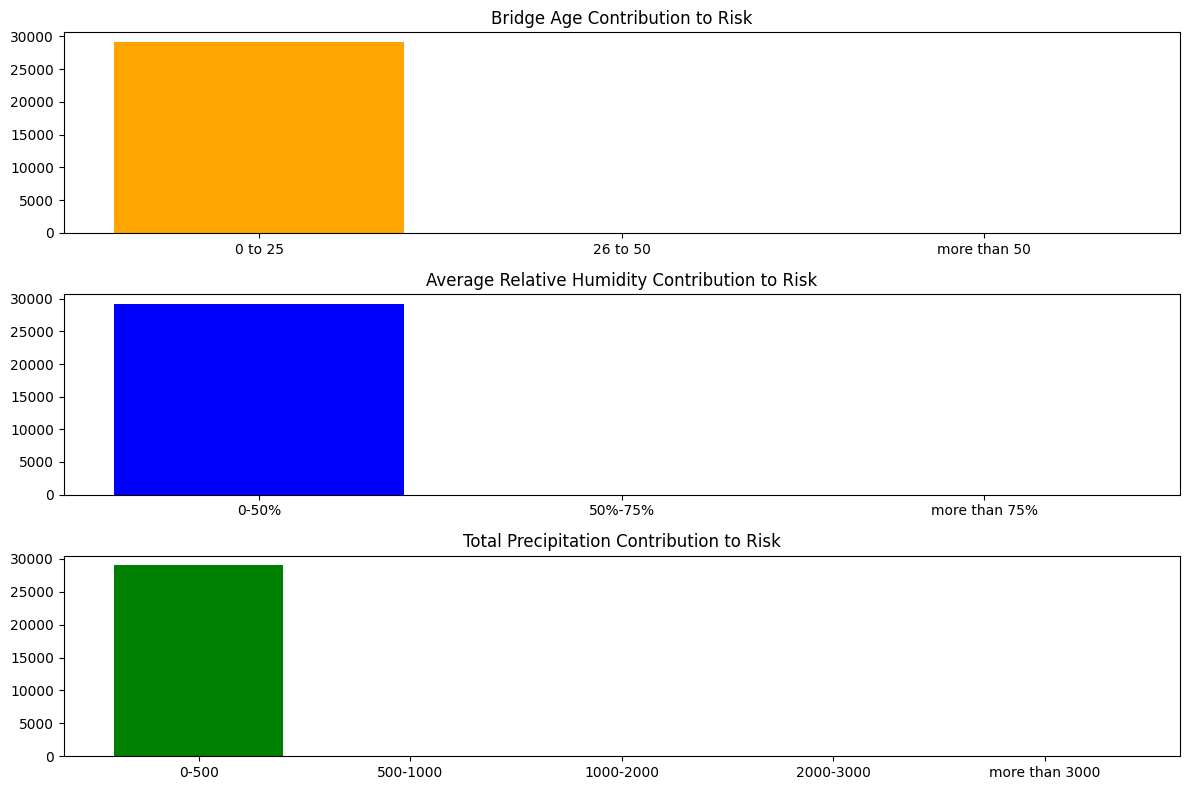

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Step 1: Load the dataset
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

# Step 2: Copy the data for encoding
X_encoded = X.copy()

# Step 3: Encode categorical variables (if necessary)
categorical_columns = ['mainspanmaterial_re', 'lanes_re', 'Bridge_Age', 'Deck_Area', 'ADT', 'structure_length',
                       'type_of_work', 'ADTT_Percent', 'avg_relative_humidity', 'total_precipitation']

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    label_encoders[col] = le

# Step 4: Categorizing the variables as per your original code

# Categorizing Bridge Age
category2 = pd.cut(X_encoded.Bridge_Age, bins=[0, 25, 50, np.inf], labels=['0 to 25', '26 to 50', 'more than 50'])

# Categorizing Deck Area
category3 = pd.cut(X_encoded.Deck_Area, bins=[0, 1000, 2000, 3000, 4000, 5000, 6000, np.inf], 
                   labels=['0 to 1000', '1000 to 2000', '2000 to 3000', '3000 to 4000', '4000 to 5000', '5000 to 6000', 'more than 6000'])

# Categorizing avg_relative_humidity
category8 = pd.cut(X_encoded.avg_relative_humidity, bins=[0, 50, 75, np.inf], labels=['0-50%', '50%-75%', 'more than 75%'])

# Categorizing total_precipitation
category9 = pd.cut(X_encoded.total_precipitation, bins=[0, 500, 1000, 2000, 3000, np.inf], 
                   labels=['0-500', '500-1000', '1000-2000', '2000-3000', 'more than 3000'])

# Step 5: Add these categories to the dataset
X_encoded['Age_Category'] = category2
X_encoded['DeckArea_Category'] = category3
X_encoded['Humidity_Category'] = category8
X_encoded['Precipitation_Category'] = category9

# Step 6: Assign risk scores based on the categories
def assign_risk(row):
    risk = 0
    
    # Age Risk
    if row['Age_Category'] == 'more than 50':
        risk += 3  # High risk
    elif row['Age_Category'] == '26 to 50':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Humidity Risk
    if row['Humidity_Category'] == 'more than 75%':
        risk += 3  # High risk
    elif row['Humidity_Category'] == '50%-75%':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Precipitation Risk
    if row['Precipitation_Category'] == 'more than 3000':
        risk += 3  # High risk
    elif row['Precipitation_Category'] == '2000-3000':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    return risk

# Step 7: Calculate the risk score
X_encoded['risk_score'] = X_encoded.apply(assign_risk, axis=1)

# Step 8: Visualize the contribution of each factor to the overall risk
plt.figure(figsize=(12, 8))

# Plot Age Contribution
plt.subplot(3, 1, 1)
age_counts = X_encoded['Age_Category'].value_counts().sort_index()
plt.bar(age_counts.index, age_counts.values, color='orange')
plt.title('Bridge Age Contribution to Risk')

# Plot Humidity Contribution
plt.subplot(3, 1, 2)
humidity_counts = X_encoded['Humidity_Category'].value_counts().sort_index()
plt.bar(humidity_counts.index, humidity_counts.values, color='blue')
plt.title('Average Relative Humidity Contribution to Risk')

# Plot Precipitation Contribution
plt.subplot(3, 1, 3)
precipitation_counts = X_encoded['Precipitation_Category'].value_counts().sort_index()
plt.bar(precipitation_counts.index, precipitation_counts.values, color='green')
plt.title('Total Precipitation Contribution to Risk')

plt.tight_layout()
plt.show()

# Step 9: Save the final dataframe with risk scores
X_encoded.to_csv('bridge_risk_scores_categorical.csv')


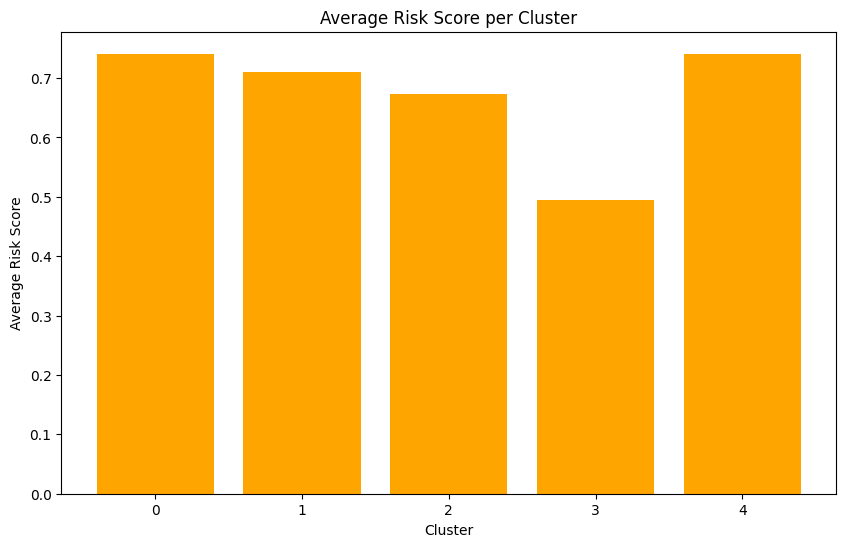

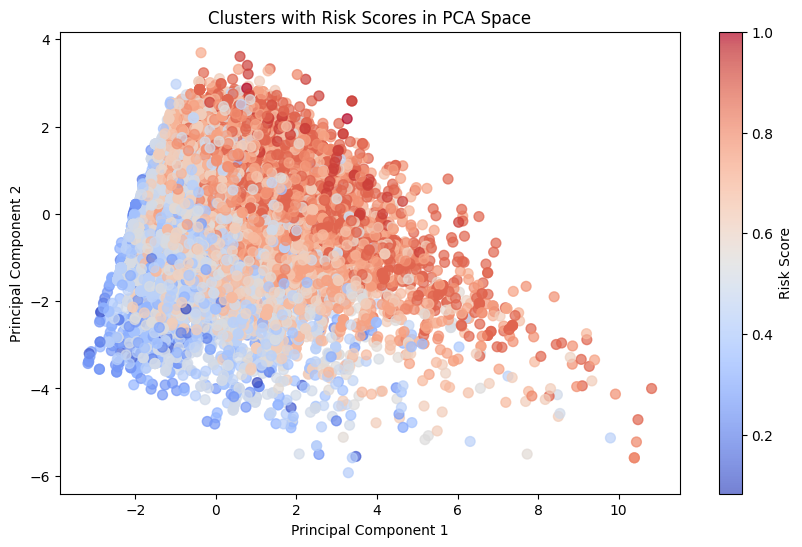

In [3]:
# Multi-Criteria Decision Analysis (MCDA)
# Define the criteria for risk assessment using the original numeric columns
criteria = ['avg_relative_humidity', 'total_precipitation', 'ADTT_Percent', 'Bridge_Age']

# Assign equal weights to the criteria (can be modified as needed)
weights = np.array([0.25, 0.25, 0.25, 0.25])

# Normalize the criteria (using the original numeric columns)
X_clustered_normalized = X_clustered.copy()
for criterion in criteria:
    X_clustered_normalized[criterion] = (X_clustered[criterion] - X_clustered[criterion].min()) / (X_clustered[criterion].max() - X_clustered[criterion].min())

# Calculate the risk score as a weighted sum of the normalized criteria
X_clustered_normalized['Risk_Score'] = X_clustered_normalized[criteria].dot(weights)

# Calculate the average risk score for each cluster
cluster_risk_scores = X_clustered_normalized.groupby('cluster')['Risk_Score'].mean().reset_index()

# Merge the risk scores back into the clustered data
X_clustered = X_clustered.merge(cluster_risk_scores, on='cluster', how='left', suffixes=('', '_Cluster'))

# Visualize the average risk score for each cluster
plt.figure(figsize=(10, 6))
plt.bar(cluster_risk_scores['cluster'], cluster_risk_scores['Risk_Score'], color='orange')
plt.xlabel('Cluster')
plt.ylabel('Average Risk Score')
plt.title('Average Risk Score per Cluster')
plt.show()

# Visualize clusters in PCA space colored by risk score
plt.figure(figsize=(10, 6))
plt.scatter(X_reduceddf['PC1'], X_reduceddf['PC2'], c=X_clustered_normalized['Risk_Score'], cmap='coolwarm', s=50, alpha=0.7)
plt.colorbar(label='Risk Score')
plt.title('Clusters with Risk Scores in PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()


In [5]:
# Separate numeric and categorical columns
numeric_columns = X_clustered.select_dtypes(include=[np.number]).columns
categorical_columns = X_clustered.select_dtypes(include=['category', 'object']).columns

# For numeric columns, calculate the mean for each cluster
cluster_numeric_characteristics = X_clustered.groupby('cluster')[numeric_columns].mean()

# For categorical columns, calculate the mode (most frequent category) for each cluster
cluster_categorical_characteristics = X_clustered.groupby('cluster')[categorical_columns].agg(lambda x: x.mode().iloc[0])

# Combine numeric and categorical characteristics into a single DataFrame
cluster_characteristics = pd.concat([cluster_numeric_characteristics, cluster_categorical_characteristics], axis=1)

# Display the cluster characteristics
print(cluster_characteristics)

# Optional: Save the cluster characteristics to a CSV file for further analysis
cluster_characteristics.to_csv('C:/Users/Elniajo/Documents/Cluster Analysis/Cluster_Characteristics.csv')


         mainspanmaterial_re  mainspandesign_re  lanes_re  Bridge_Age  \
cluster                                                                 
0                   7.060756          16.878263  2.426193    2.836184   
1                   3.297265           9.880210  1.945420    2.780246   
2                   8.196733          18.141068  1.650264    2.760810   
3                   7.066878          17.568911  1.840940    2.824974   
4                   6.625000          14.052778  3.630556    2.861111   

         Deck_Area       ADT  structure_length  type_of_work  ADTT_Percent  \
cluster                                                                      
0         5.919217  1.000000          2.025428      3.451170      3.326958   
1         2.104861  1.000000          1.006688      2.595127      2.932043   
2         1.799746  1.000000          1.006065      2.142536      2.571023   
3         2.022142  1.000000          1.025305      1.951951      2.124718   
4         5.786111  

<Figure size 1000x600 with 0 Axes>

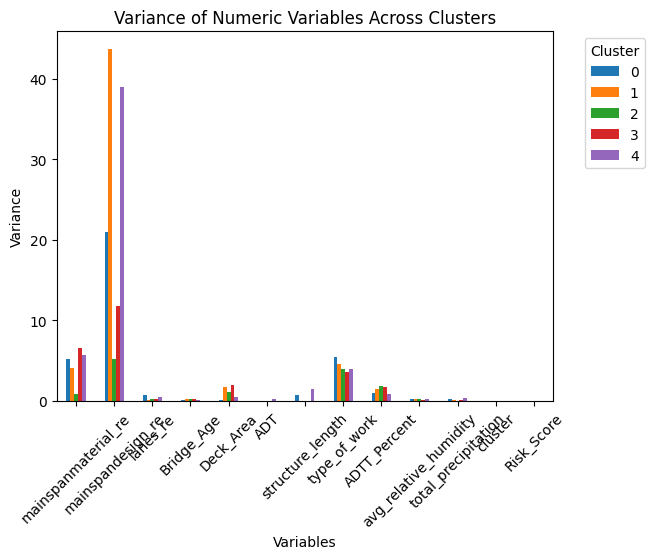

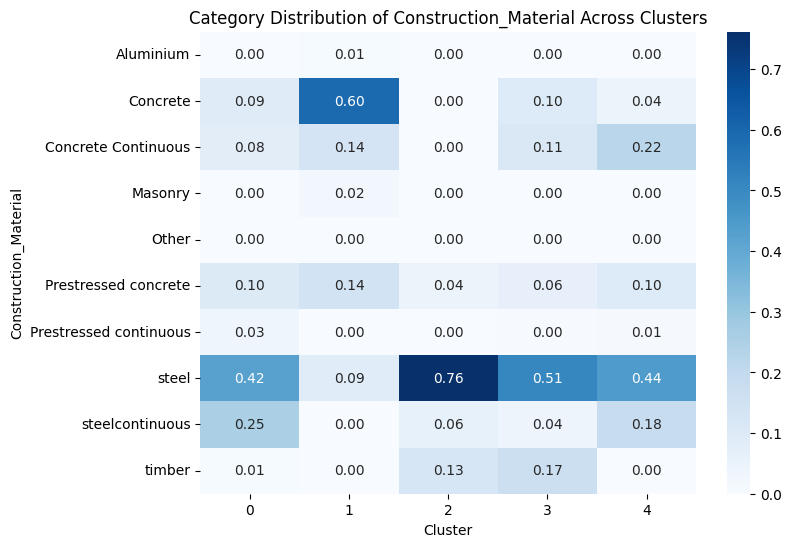

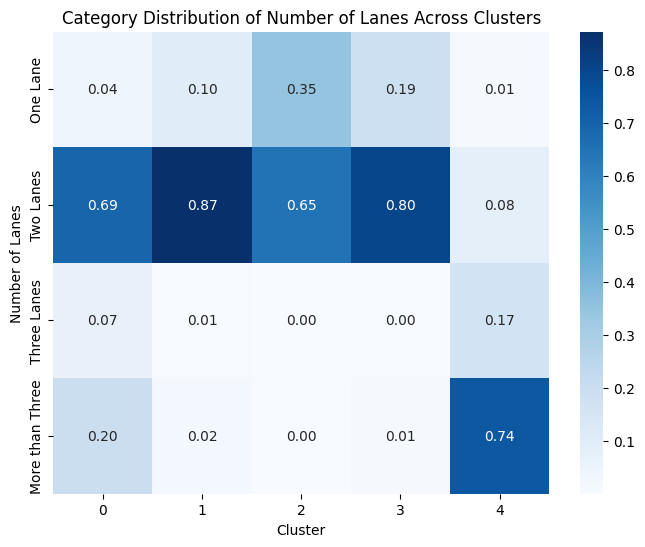

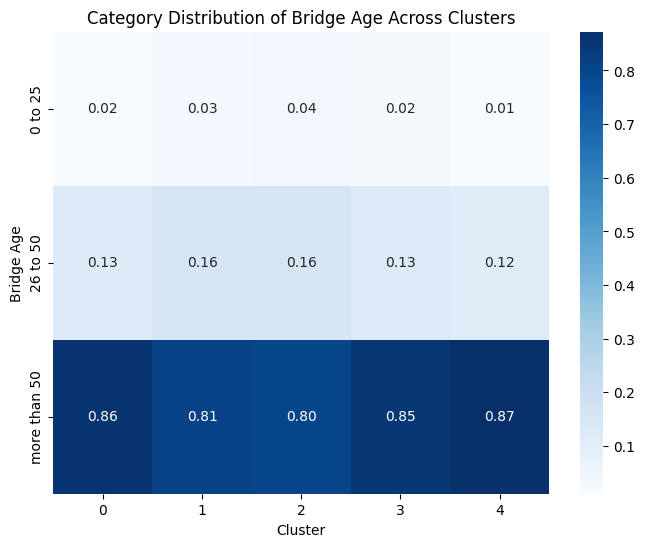

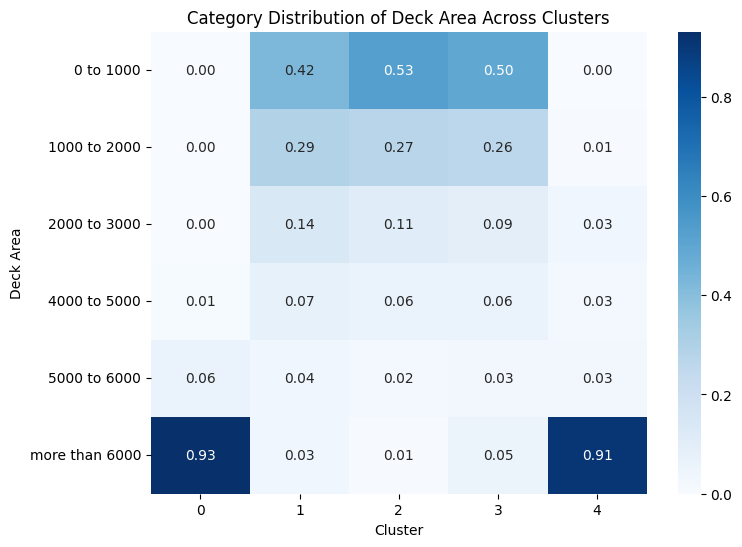

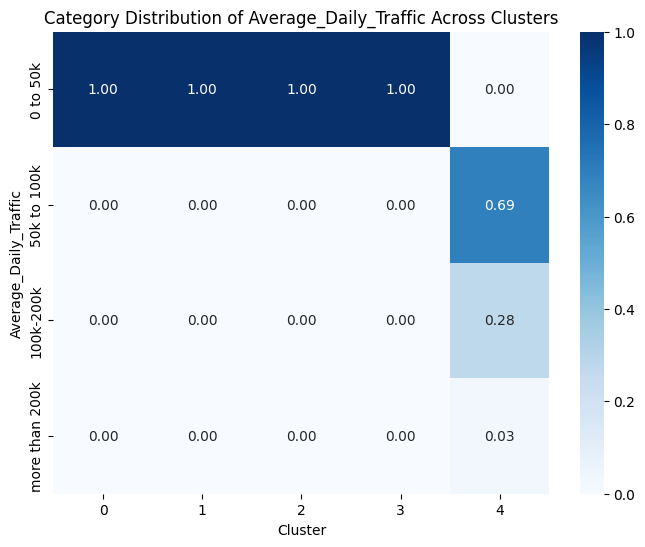

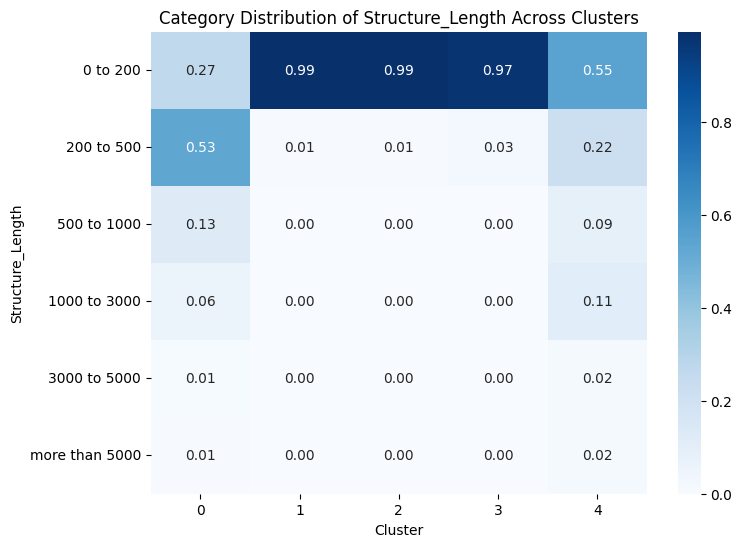

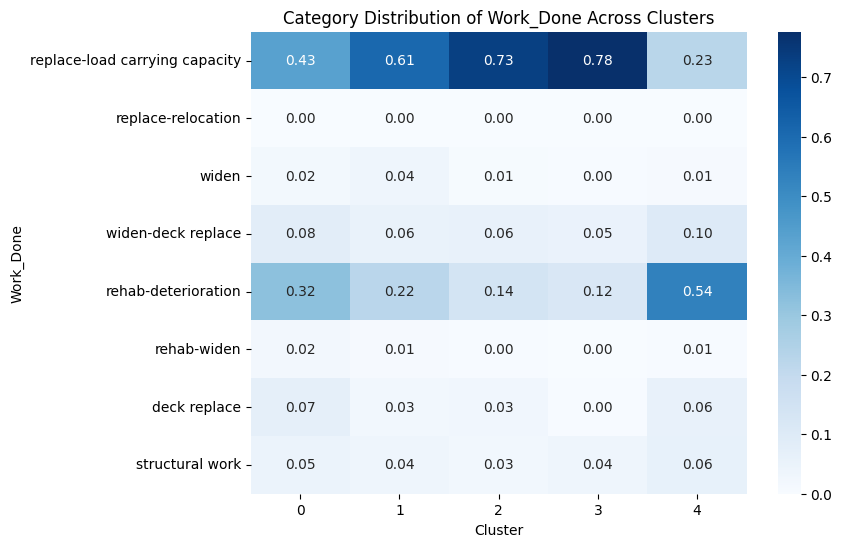

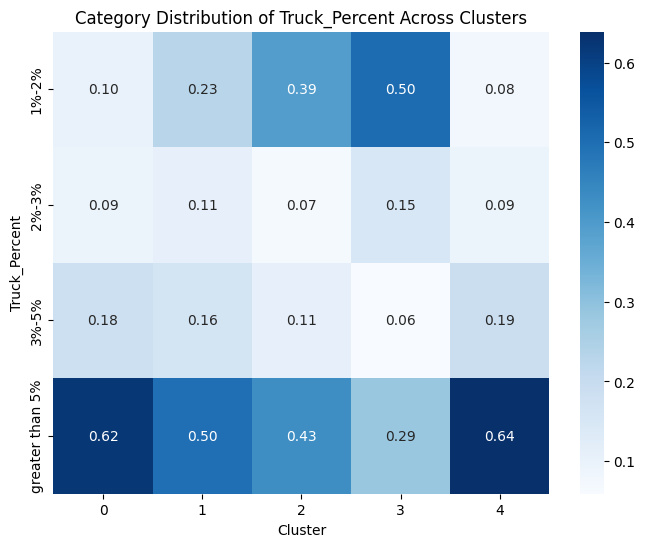

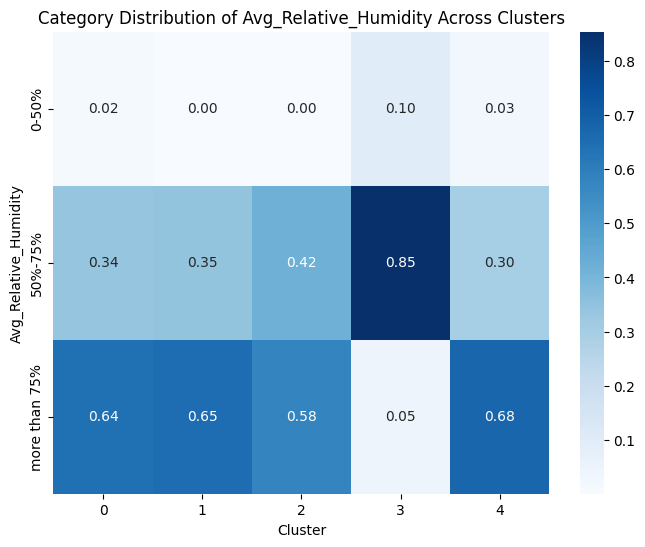

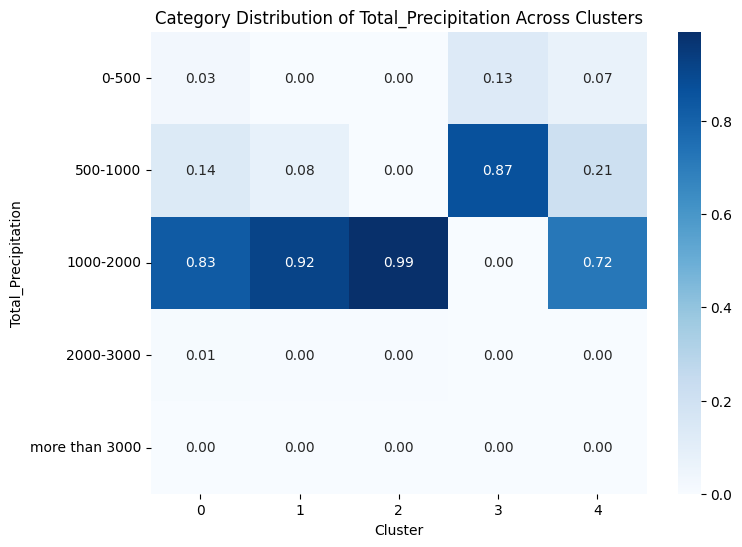

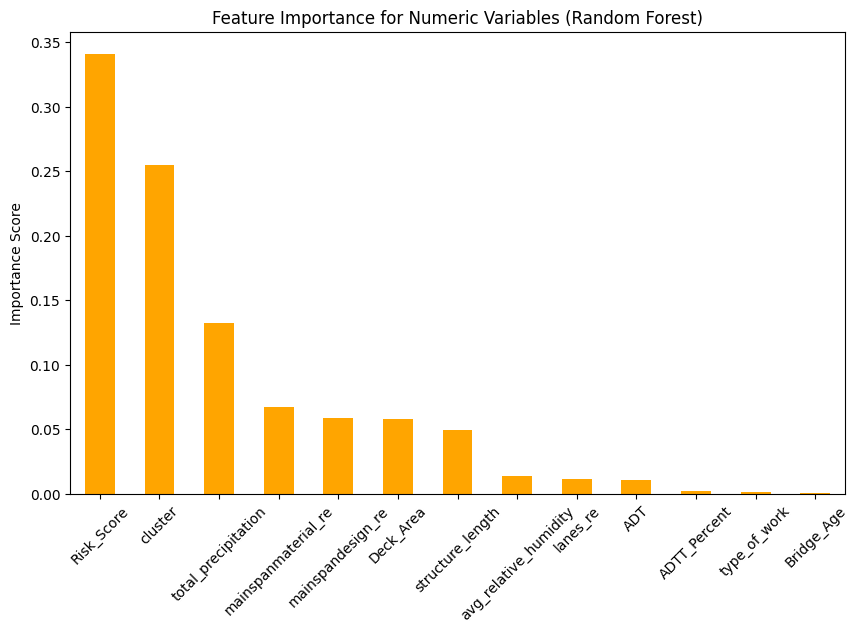

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# Separate numeric and categorical columns
numeric_columns = X_clustered.select_dtypes(include=[np.number]).columns
categorical_columns = X_clustered.select_dtypes(include=['category', 'object']).columns

# 1. Plot variance for numeric variables across clusters
numeric_cluster_variance = X_clustered.groupby('cluster')[numeric_columns].var()

# Plot the variance of each numeric variable across clusters
plt.figure(figsize=(10, 6))
numeric_cluster_variance.T.plot(kind='bar', stacked=False)
plt.title('Variance of Numeric Variables Across Clusters')
plt.xlabel('Variables')
plt.ylabel('Variance')
plt.xticks(rotation=45)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# 2. Visualize category distribution in categorical variables
# Create a heatmap for each categorical variable's distribution across clusters
for cat_col in categorical_columns:
    cat_distribution = pd.crosstab(X_clustered[cat_col], X_clustered['cluster'], normalize='columns')
    plt.figure(figsize=(8, 6))
    sns.heatmap(cat_distribution, annot=True, cmap='Blues', fmt='.2f')
    plt.title(f'Category Distribution of {cat_col} Across Clusters')
    plt.xlabel('Cluster')
    plt.ylabel(f'{cat_col}')
    plt.show()

# 3. Feature Importance for numeric variables using Random Forest
# Define the features (X) and target (y)
X_rf = X_clustered[numeric_columns]
y_rf = X_clustered['cluster']

# Fit a RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_rf, y_rf)

# Get feature importances
feature_importances = pd.Series(rf.feature_importances_, index=numeric_columns).sort_values(ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
feature_importances.plot(kind='bar', color='orange')
plt.title('Feature Importance for Numeric Variables (Random Forest)')
plt.ylabel('Importance Score')
plt.xticks(rotation=45)
plt.show()


Final Prioritization of Projects:
   Project  Risk_Score  Criticality_Score  Final_Priority_Score  Rank
0  Route_A       0.504               0.78                 1.284   1.0
1  Route_B       0.432               0.76                 1.192   2.0
2  Route_C       0.378               0.74                 1.118   3.0
3  Route_D       0.240               0.63                 0.870   4.0
4  Route_E       0.175               0.59                 0.765   5.0


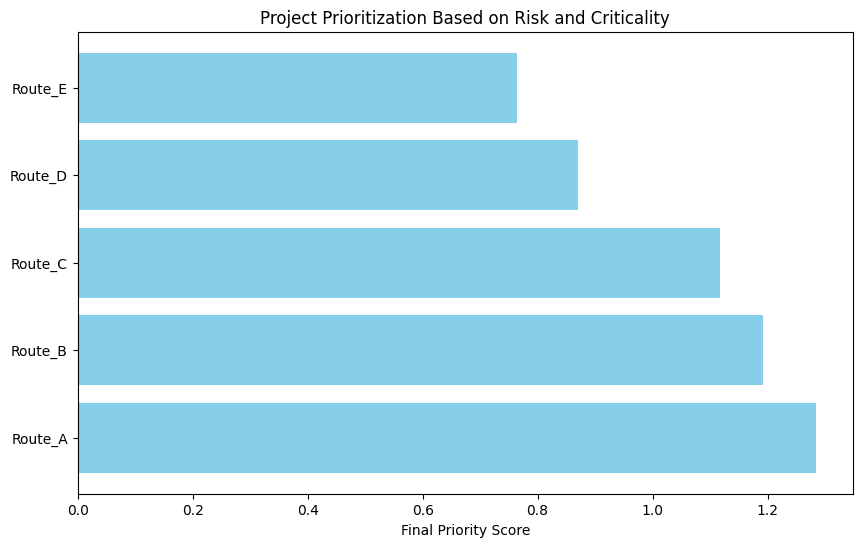

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Sample Data Preparation
# You can replace this with the actual dataset you're using
# Example dataframe with projects and necessary columns
data = {
    'Project': ['Route_A', 'Route_B', 'Route_C', 'Route_D', 'Route_E'],
    'Probability_Threat': [0.8, 0.6, 0.9, 0.5, 0.7],  # From climate projections
    'Vulnerability': [0.7, 0.9, 0.6, 0.8, 0.5],  # Infrastructure condition
    'Consequence_Impact': [0.9, 0.8, 0.7, 0.6, 0.5],  # Severity of impact
    'Functional_Importance': [0.9, 0.7, 0.8, 0.6, 0.5],  # Economic significance
    'Social_Impact': [0.6, 0.9, 0.5, 0.7, 0.8],  # Social equity or impact on vulnerable populations
    'Emergency_Routes': [0.8, 0.7, 0.9, 0.6, 0.5]  # Priority for emergency response
}

df = pd.DataFrame(data)

# Step 2: Calculate Risk Score
# Risk = Probability of Threat × Vulnerability × Consequence of Impact
df['Risk_Score'] = df['Probability_Threat'] * df['Vulnerability'] * df['Consequence_Impact']

# Step 3: Calculate Criticality Score
# Criticality_Score = Weighted sum of functional importance, social impact, and emergency importance
df['Criticality_Score'] = (
    0.4 * df['Functional_Importance'] + 
    0.3 * df['Social_Impact'] + 
    0.3 * df['Emergency_Routes']
)

# Step 4: Combine Risk and Criticality Scores into Final Priority Score
df['Final_Priority_Score'] = df['Risk_Score'] + df['Criticality_Score']

# Step 5: Rank projects based on final priority score (higher score = higher priority)
df['Rank'] = df['Final_Priority_Score'].rank(ascending=False)

# Step 6: Sort dataframe by rank for better viewing
df_sorted = df.sort_values(by='Rank', ascending=True)

# Step 7: Display the final ranking of projects
print("Final Prioritization of Projects:")
print(df_sorted[['Project', 'Risk_Score', 'Criticality_Score', 'Final_Priority_Score', 'Rank']])

# Step 8: Visualization of Project Prioritization
plt.figure(figsize=(10, 6))
plt.barh(df_sorted['Project'], df_sorted['Final_Priority_Score'], color='skyblue')
plt.xlabel('Final Priority Score')
plt.title('Project Prioritization Based on Risk and Criticality')
plt.show()


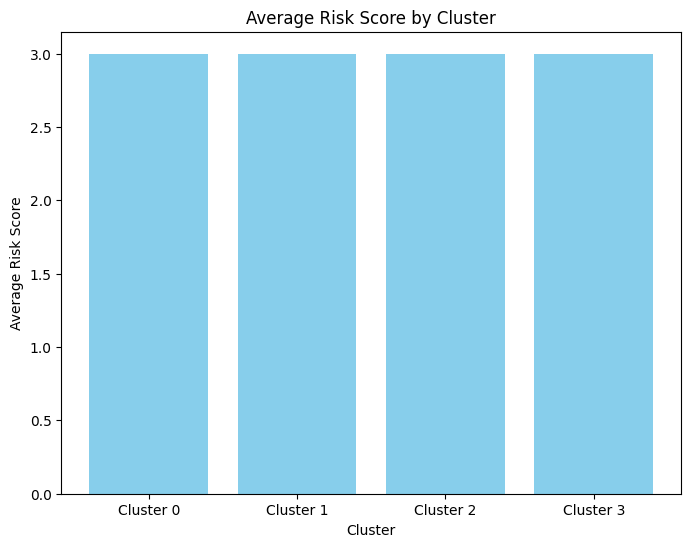

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans

# Step 1: Load the dataset
X = pd.read_csv('NBI_model_only2.csv')

# Step 2: Copy the data for encoding
X_encoded = X.copy()

# Step 3: Encode categorical variables (if necessary)
categorical_columns = ['mainspanmaterial_re', 'lanes_re', 'Bridge_Age', 'Deck_Area', 'ADT', 'structure_length',
                       'type_of_work', 'ADTT_Percent', 'avg_relative_humidity', 'total_precipitation']

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    label_encoders[col] = le

# Step 4: Categorizing the variables as per the given criteria

# Categorizing Bridge Age
category2 = pd.cut(X_encoded.Bridge_Age, bins=[0, 25, 50, np.inf], labels=['0 to 25', '26 to 50', 'more than 50'])

# Categorizing Deck Area
category3 = pd.cut(X_encoded.Deck_Area, bins=[0, 1000, 2000, 3000, 4000, 5000, 6000, np.inf], 
                   labels=['0 to 1000', '1000 to 2000', '2000 to 3000', '3000 to 4000', '4000 to 5000', '5000 to 6000', 'more than 6000'])

# Categorizing avg_relative_humidity
category8 = pd.cut(X_encoded.avg_relative_humidity, bins=[0, 50, 75, np.inf], labels=['0-50%', '50%-75%', 'more than 75%'])

# Categorizing total_precipitation
category9 = pd.cut(X_encoded.total_precipitation, bins=[0, 500, 1000, 2000, 3000, np.inf], 
                   labels=['0-500', '500-1000', '1000-2000', '2000-3000', 'more than 3000'])

# Step 5: Add these categories to the dataset
X_encoded['Age_Category'] = category2
X_encoded['DeckArea_Category'] = category3
X_encoded['Humidity_Category'] = category8
X_encoded['Precipitation_Category'] = category9

# Step 6: Assign risk scores based on the categories
def assign_risk(row):
    risk = 0
    
    # Age Risk
    if row['Age_Category'] == 'more than 50':
        risk += 3  # High risk
    elif row['Age_Category'] == '26 to 50':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Humidity Risk
    if row['Humidity_Category'] == 'more than 75%':
        risk += 3  # High risk
    elif row['Humidity_Category'] == '50%-75%':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Precipitation Risk
    if row['Precipitation_Category'] == 'more than 3000':
        risk += 3  # High risk
    elif row['Precipitation_Category'] == '2000-3000':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    return risk

# Step 7: Calculate the risk score
X_encoded['risk_score'] = X_encoded.apply(assign_risk, axis=1)

# Step 8: Perform clustering using K-Means
kmeans = KMeans(n_clusters=4, random_state=42)
X_encoded['cluster'] = kmeans.fit_predict(X_encoded[['Bridge_Age', 'Deck_Area', 'avg_relative_humidity', 'total_precipitation']])

# Step 9: Calculate the average risk score for each cluster
cluster_risk_scores = X_encoded.groupby('cluster')['risk_score'].mean()

# Step 10: Visualize the risk scores for each cluster
plt.figure(figsize=(8, 6))
plt.bar(cluster_risk_scores.index, cluster_risk_scores.values, color='skyblue')
plt.xlabel('Cluster')
plt.ylabel('Average Risk Score')
plt.title('Average Risk Score by Cluster')
plt.xticks(ticks=range(len(cluster_risk_scores)), labels=[f'Cluster {i}' for i in range(len(cluster_risk_scores))])
plt.show()

# Step 11: Save the final dataframe with risk scores and clusters
X_encoded.to_csv('bridge_risk_scores_clusters.csv', index=False)


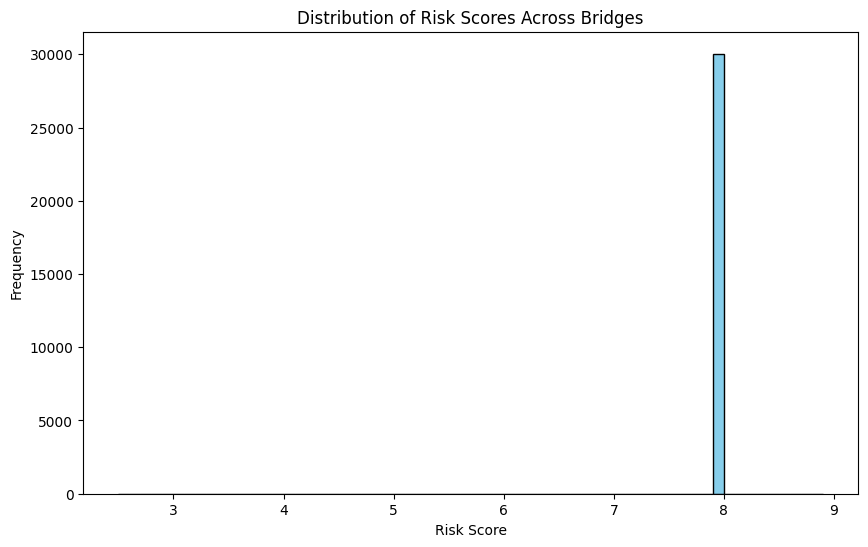

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Step 1: Load the dataset
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

# Step 2: Copy the data for encoding
X_encoded = X.copy()

# Step 3: Encode categorical variables
categorical_columns = ['mainspanmaterial_re', 'lanes_re', 'Bridge_Age', 'Deck_Area', 'ADT', 'structure_length',
                       'type_of_work', 'ADTT_Percent', 'avg_relative_humidity', 'total_precipitation']

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    label_encoders[col] = le

# Step 4: Categorizing the variables based on existing category info

# No need to categorize ADT, structural material, etc., they are already in categories
# ADT, for example, would be treated as predefined categories

# Step 5: Add categorical information to other variables (if necessary)
# Example categories for age, humidity, and precipitation already defined before
category2 = pd.cut(X_encoded.Bridge_Age, bins=[0, 25, 50, np.inf], labels=['0 to 25', '26 to 50', 'more than 50'])
category8 = pd.cut(X_encoded.avg_relative_humidity, bins=[0, 50, 75, np.inf], labels=['0-50%', '50%-75%', 'more than 75%'])
category9 = pd.cut(X_encoded.total_precipitation, bins=[0, 500, 1000, 2000, 3000, np.inf], labels=['0-500', '500-1000', '1000-2000', '2000-3000', 'more than 3000'])

# Step 6: Add these categories to the dataset
X_encoded['Age_Category'] = category2
X_encoded['Humidity_Category'] = category8
X_encoded['Precipitation_Category'] = category9

# Step 7: Assign risk scores based on all categorized variables
def assign_risk(row):
    risk = 0
    
    # Age Risk
    if row['Age_Category'] == 'more than 50':
        risk += 3  # High risk
    elif row['Age_Category'] == '26 to 50':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Humidity Risk
    if row['Humidity_Category'] == 'more than 75%':
        risk += 3  # High risk
    elif row['Humidity_Category'] == '50%-75%':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Precipitation Risk
    if row['Precipitation_Category'] == 'more than 3000':
        risk += 3  # High risk
    elif row['Precipitation_Category'] == '2000-3000':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # ADT Risk (Categorical): Assuming higher ADT indicates more traffic
    if row['ADT'] == 'more than 10000':
        risk += 3  # High risk
    elif row['ADT'] == '5000 to 10000':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Structural Material Risk (Categorical)
    if row['mainspanmaterial_re'] == 'steel':
        risk += 2  # Medium risk
    elif row['mainspanmaterial_re'] == 'concrete':
        risk += 1  # Low risk
    else:
        risk += 3  # High risk for other materials
    
    # Structure Length Risk (Categorical): Assuming longer bridges are at higher risk
    if row['structure_length'] == 'more than 1000':
        risk += 3  # High risk
    elif row['structure_length'] == '500 to 1000':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    return risk

# Step 8: Calculate the risk score
X_encoded['risk_score'] = X_encoded.apply(assign_risk, axis=1)

# Step 9: Visualize the distribution of risk scores
plt.figure(figsize=(10, 6))
plt.hist(X_encoded['risk_score'], bins=np.arange(2.5, X_encoded['risk_score'].max() + 1, 0.1), color='skyblue', edgecolor='black')
plt.title('Distribution of Risk Scores Across Bridges')
plt.xlabel('Risk Score')
plt.ylabel('Frequency')
plt.show()

# Step 10: Save the final dataframe with risk scores
X_encoded.to_csv('bridge_risk_scores_updated.csv')


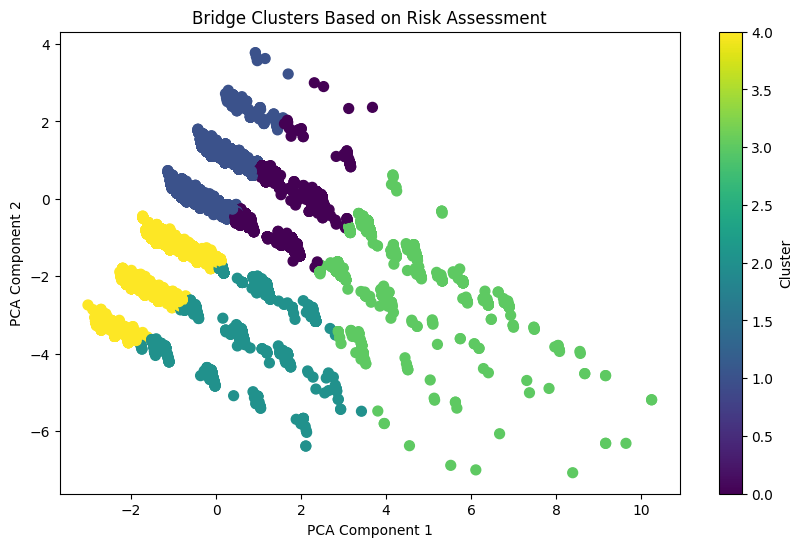

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 1: Load the dataset with the risk scores
X = pd.read_csv('bridge_risk_scores_updated.csv', index_col='Bridge_condition')

# Step 2: Prepare the data for clustering (use the risk score and relevant variables)
features_for_clustering = ['risk_score', 'ADT', 'Bridge_Age', 'Deck_Area', 'avg_relative_humidity', 'total_precipitation', 'structure_length', 'mainspanmaterial_re']
X_clustering = X[features_for_clustering]

# Step 3: Normalize the data before PCA and K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clustering)

# Step 4: Perform PCA to reduce dimensionality for clustering
pca = PCA(n_components=2)  # Reduce to 2 components for easy visualization
X_pca = pca.fit_transform(X_scaled)

# Step 5: Apply K-Means Clustering
kmeans = KMeans(n_clusters=5, random_state=42)  # You can adjust the number of clusters
clusters = kmeans.fit_predict(X_pca)

# Step 6: Add the clusters to the dataset
X['cluster'] = clusters

# Step 7: Visualize the clusters
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=50)
plt.title('Bridge Clusters Based on Risk Assessment')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster')
plt.show()

# Step 8: Save the dataset with clusters
X.to_csv('bridge_risk_clusters.csv')


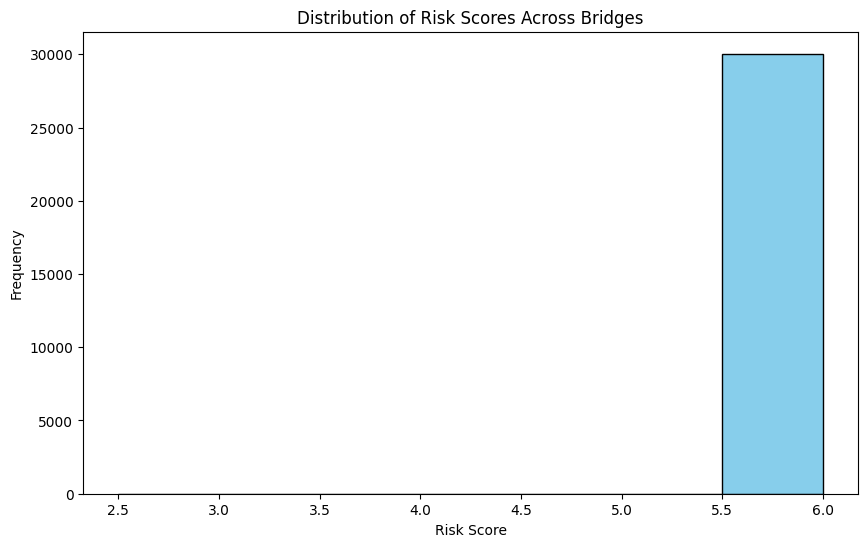

In [20]:
# Updated Binning and Categorization with Correct Bin Sizes
category2 = pd.cut(X_encoded.Bridge_Age, bins=[0, 25, 50, np.inf], labels=['0 to 25', '26 to 50', 'more than 50'])

category3 = pd.cut(X_encoded.Deck_Area, bins=[0, 1000, 2000, 3000, 4000, 5000, 6000, np.inf], 
                   labels=['0 to 1000', '1000 to 2000', '2000 to 3000', '3000 to 4000', '4000 to 5000', '5000 to 6000', 'more than 6000'])

category4 = pd.cut(X_encoded.ADT, bins=[0, 50000, 100000, 200000, np.inf], 
                   labels=['0 to 50k', '50k to 100k', '100k-200k', 'more than 200k'])

category5 = pd.cut(X_encoded.structure_length, bins=[0, 200, 500, 1000, 3000, 5000, np.inf], 
                   labels=['0 to 200', '200 to 500', '500 to 1000', '1000 to 3000', '3000 to 5000', 'more than 5000'])

category8 = pd.cut(X_encoded.avg_relative_humidity, bins=[0, 50, 75, np.inf], 
                   labels=['0-50%', '50%-75%', 'more than 75%'])

category9 = pd.cut(X_encoded.total_precipitation, bins=[0, 500, 1000, 2000, 3000, np.inf], 
                   labels=['0-500', '500-1000', '1000-2000', '2000-3000', 'more than 3000'])

# Update the dataset with new categories
X_encoded['Age_Category'] = category2
X_encoded['DeckArea_Category'] = category3
X_encoded['ADT_Category'] = category4
X_encoded['StructureLength_Category'] = category5
X_encoded['Humidity_Category'] = category8
X_encoded['Precipitation_Category'] = category9

# Adjusted Risk Calculation
def assign_risk(row):
    risk = 0
    
    # Age Risk
    if row['Age_Category'] == 'more than 50':
        risk += 3
    elif row['Age_Category'] == '26 to 50':
        risk += 2
    else:
        risk += 1
    
    # Deck Area Risk
    if row['DeckArea_Category'] == 'more than 6000':
        risk += 3
    elif row['DeckArea_Category'] == '5000 to 6000':
        risk += 2
    else:
        risk += 1
    
    # ADT Risk
    if row['ADT_Category'] == 'more than 200k':
        risk += 3
    elif row['ADT_Category'] == '100k-200k':
        risk += 2
    else:
        risk += 1
    
    # Humidity Risk
    if row['Humidity_Category'] == 'more than 75%':
        risk += 3
    elif row['Humidity_Category'] == '50%-75%':
        risk += 2
    else:
        risk += 1
    
    # Precipitation Risk
    if row['Precipitation_Category'] == 'more than 3000':
        risk += 3
    elif row['Precipitation_Category'] == '2000-3000':
        risk += 2
    else:
        risk += 1

    # Structure Length Risk
    if row['StructureLength_Category'] == 'more than 5000':
        risk += 3
    elif row['StructureLength_Category'] == '3000 to 5000':
        risk += 2
    else:
        risk += 1

    return risk

# Recalculate the risk score based on updated categories
X_encoded['risk_score'] = X_encoded.apply(assign_risk, axis=1)

# Visualize the updated risk distribution
plt.figure(figsize=(10, 6))
plt.hist(X_encoded['risk_score'], bins=np.arange(2.5, X_encoded['risk_score'].max() + 0.5, 0.5), color='skyblue', edgecolor='black')
plt.title('Distribution of Risk Scores Across Bridges')
plt.xlabel('Risk Score')
plt.ylabel('Frequency')
plt.show()


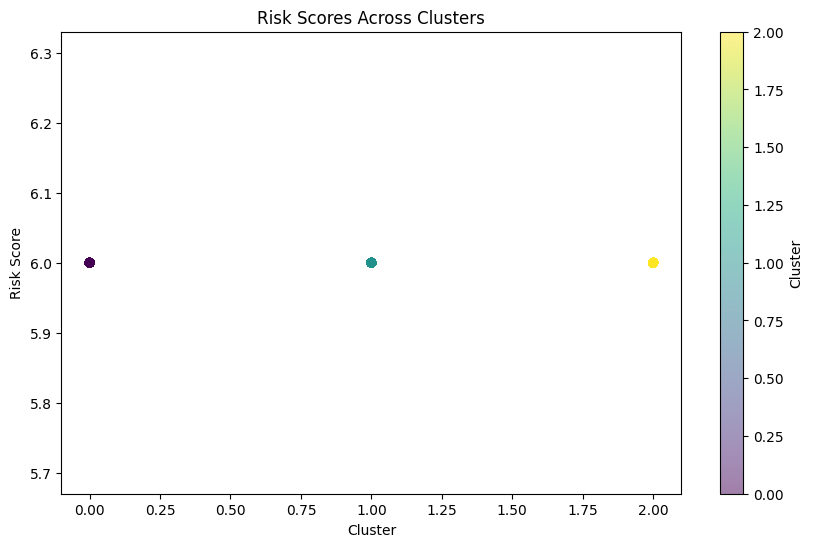

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Step 1: Load the dataset
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

# Step 2: Copy the data for encoding
X_encoded = X.copy()

# Step 3: Encode categorical variables (if necessary)
categorical_columns = ['mainspanmaterial_re', 'lanes_re', 'Bridge_Age', 'Deck_Area', 'ADT', 'structure_length',
                       'type_of_work', 'ADTT_Percent', 'avg_relative_humidity', 'total_precipitation']

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    label_encoders[col] = le

# Step 4: Normalize the data for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Step 5: Apply K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=0)  # Example with 3 clusters
X_encoded['Cluster'] = kmeans.fit_predict(X_scaled)

# Step 6: Incorporate PCI (Pavement Condition Index)
# Assuming 'PCI' is a column in the dataset
# Categorize PCI values into risk categories
# Adjust PCI risk levels as necessary for your data

# Step 7: Categorize the variables
# Categorizing Bridge Age
category2 = pd.cut(X_encoded.Bridge_Age, bins=[0, 50, np.inf], labels=['50 or less', 'more than 50'])

# Categorizing Deck Area
category3 = pd.cut(X_encoded.Deck_Area, bins=[0, 1000, 2000, 3000, 4000, 5000, 6000, np.inf], 
                   labels=['0 to 1000', '1000 to 2000', '2000 to 3000', '3000 to 4000', '4000 to 5000', '5000 to 6000', 'more than 6000'])

# Categorizing ADT
category4 = pd.cut(X_encoded.ADT, bins=[0, 50000, 100000, 200000, np.inf], 
                   labels=['0 to 50k', '50k to 100k', '100k-200k', 'more than 200k'])

# Categorizing Structure Length
category5 = pd.cut(X_encoded.structure_length, bins=[0, 200, 500, 1000, 3000, 5000, np.inf], 
                   labels=['0 to 200', '200 to 500', '500 to 1000', '1000 to 3000', '3000 to 5000', 'more than 5000'])

# Categorizing avg_relative_humidity
category8 = pd.cut(X_encoded.avg_relative_humidity, bins=[0, 50, 75, np.inf], labels=['0-50%', '50%-75%', 'more than 75%'])

# Categorizing total_precipitation
category9 = pd.cut(X_encoded.total_precipitation, bins=[0, 500, 1000, 2000, 3000, np.inf], 
                   labels=['0-500', '500-1000', '1000-2000', '2000-3000', 'more than 3000'])

# Step 8: Add these categories to the dataset
X_encoded['Age_Category'] = category2
X_encoded['DeckArea_Category'] = category3
X_encoded['ADT_Category'] = category4
X_encoded['StructureLength_Category'] = category5
X_encoded['Humidity_Category'] = category8
X_encoded['Precipitation_Category'] = category9

# Step 9: Assign risk scores based on the categories within each cluster
def assign_risk(row):
    risk = 0
    
    # Age Risk
    if row['Age_Category'] == 'more than 50':
        risk += 3  # High risk
    else:
        risk += 1  # Low risk
    
    # Deck Area Risk
    if row['DeckArea_Category'] == 'more than 6000':
        risk += 3  # High risk
    elif row['DeckArea_Category'] in ['5000 to 6000', '4000 to 5000']:
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # ADT Risk
    if row['ADT_Category'] == 'more than 200k':
        risk += 3  # High risk
    elif row['ADT_Category'] == '100k-200k':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Humidity Risk
    if row['Humidity_Category'] == 'more than 75%':
        risk += 3  # High risk
    elif row['Humidity_Category'] == '50%-75%':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Precipitation Risk
    if row['Precipitation_Category'] == 'more than 3000':
        risk += 3  # High risk
    elif row['Precipitation_Category'] == '2000-3000':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    # Structure Length Risk
    if row['StructureLength_Category'] == 'more than 5000':
        risk += 3  # High risk
    elif row['StructureLength_Category'] == '3000 to 5000':
        risk += 2  # Medium risk
    else:
        risk += 1  # Low risk
    
    return risk

# Step 10: Calculate the risk score for each cluster
X_encoded['risk_score'] = X_encoded.apply(assign_risk, axis=1)

# Step 11: Visualize the clusters and their risk distribution
plt.figure(figsize=(10, 6))
plt.scatter(X_encoded['Cluster'], X_encoded['risk_score'], c=X_encoded['Cluster'], cmap='viridis', alpha=0.5)
plt.title('Risk Scores Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Risk Score')
plt.colorbar(label='Cluster')
plt.show()

# Save the results
X_encoded.to_csv('clustered_bridge_risk_scores.csv')


In [ ]:
3